# Сэмплирование I: отбор, марковские цепи и алгоритм Гиббса

ИППИ РАН · Байесовские методы машинного обучения · Осень 2026

Заполненный ноутбук для 30-минутной демонстрации после 60 минут работы у доски.
Три примера показывают, что означает корректность сэмплера и почему правильное
стационарное распределение ещё не гарантирует полезную конечную выборку.

| Время демонстрации | Пример | На что смотреть |
|---|---|---|
| 0–8 мин | Rejection sampling: постериор монеты | Геометрия отбора, независимость принятых точек, стоимость |
| 8–15 мин | Конечные цепи | Стационарность, периодичность, приводимость, обратимость |
| 15–30 мин | Гиббс для коррелированной нормали | Условные распределения, траектория, корреляция и ошибка среднего |

Все реализации заполнены, результаты сохранены реальным запуском. Данные
генерируются локально. Нужны Python 3.9+, NumPy, SciPy, Matplotlib, IPython и
Jupyter. Выполняйте ячейки сверху вниз. Приложение с байесовской моделью
нормальных наблюдений находится вне 30-минутного маршрута.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import betaln
from scipy.stats import beta, norm, gamma
from IPython.display import display, Markdown

SEED = 2026
ASSETS = Path('assets')
ASSETS.mkdir(exist_ok=True)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (10, 3.5), 'axes.grid': True,
                     'grid.alpha': .2, 'font.size': 10,
                     'pdf.fonttype': 42, 'savefig.bbox': 'tight'})

def table(headers, rows):
    def fmt(value):
        return f'{value:.5g}' if isinstance(value, (float, np.floating)) else str(value)
    lines = ['| ' + ' | '.join(headers) + ' |',
             '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines.extend('| ' + ' | '.join(fmt(x) for x in row) + ' |' for row in rows)
    display(Markdown('\n'.join(lines)))

def save_show(fig, name):
    fig.tight_layout()
    fig.savefig(ASSETS / (name + '.pdf'))
    plt.show()


## 1. Независимые постериорные точки через отбор · 0–8 минут

У монеты неизвестна вероятность орла $\theta$. Априорное распределение
$\operatorname{Beta}(2,2)$; наблюдаем один орёл и пять решек. По формуле Байеса
$$\widetilde\pi(\theta)=\theta^2(1-\theta)^6\mathbf1_{(0,1)}(\theta),
\qquad \pi(\theta)=\frac{\widetilde\pi(\theta)}Z=\operatorname{Beta}(3,7).$$
Здесь $Z=B(3,7)=1/252$ нормирует именно выбранное ядро: константа априорной
плотности в него не включена.

Берём $q(\theta)=\mathbf1_{(0,1)}(\theta)$. Условие глобальной огибающей:
$\widetilde\pi(\theta)\le Mq(\theta)$ для всех $\theta$. Из
$$\frac{d}{d\theta}\log\widetilde\pi(\theta)
=\frac2\theta-\frac6{1-\theta}=0$$
получаем максимум при $\theta=1/4$ и
$$M=(1/4)^2(3/4)^6.$$
Принимаем $X\sim q$ тогда и только тогда, когда независимое $U\sim U(0,1)$
удовлетворяет $U<\widetilde\pi(X)/(Mq(X))$. Вероятность принятия равна $Z/M$.
Принятые точки имеют плотность $\pi$ и независимы, если независимы испытания.

Точные ориентиры:
$$\mathbb E\theta=0.3,\qquad
\operatorname{Var}(\theta)=21/1100,\qquad
\Pr(\theta>1/2)=23/256.$$
В решении об отборе $Z$ не используется. Точный постериор нужен здесь для проверки.


In [2]:
def log_target(theta):
    theta = np.asarray(theta, dtype=float)
    inside = (theta > 0) & (theta < 1)
    safe = np.where(inside, theta, .5)
    return np.where(inside, 2*np.log(safe) + 6*np.log1p(-safe), -np.inf)

Z = np.exp(betaln(3, 7))
M = .25**2 * .75**6
P_ACCEPT = Z/M
EXACT_MEAN = .3
EXACT_VAR = 21/1100
EXACT_TAIL = 23/256

def rejection_beta(n, rng, max_trials=2_000_000):
    """Stop at exactly n accepted draws; count every evaluated proposal."""
    if n < 1 or int(n) != n:
        raise ValueError('n должно быть положительным целым')
    accepted = np.empty(n)
    trials = 0
    kept = 0
    while kept < n and trials < max_trials:
        x = rng.random()
        u = rng.random()
        trials += 1
        if np.log(u) < log_target(x) - np.log(M):
            accepted[kept] = x
            kept += 1
    if kept != n:
        raise RuntimeError('Исчерпан лимит предложений')
    return accepted, trials

# Deterministic checks of the analytic envelope and reference moments.
grid = np.linspace(0, 1, 1001)
assert np.all(np.exp(log_target(grid)) <= M*(1+1e-12))
np.testing.assert_allclose(Z, 1/252)
np.testing.assert_allclose(beta.mean(3, 7), EXACT_MEAN)
np.testing.assert_allclose(beta.var(3, 7), EXACT_VAR)
np.testing.assert_allclose(beta.sf(.5, 3, 7), EXACT_TAIL)
assert np.isneginf(log_target(np.array([-1, 0, 1, 2]))).all()

rejection_draws, proposals = rejection_beta(6000, np.random.default_rng(SEED))
table(['Величина', 'Эксперимент', 'Точный ориентир'], [
    ['Доля принятых', len(rejection_draws)/proposals, P_ACCEPT],
    ['Предложений на принятую точку', proposals/len(rejection_draws), 1/P_ACCEPT],
    ['Среднее theta', rejection_draws.mean(), EXACT_MEAN],
    ['P(theta > 1/2)', np.mean(rejection_draws > .5), EXACT_TAIL],
    ['SE среднего, iid', rejection_draws.std(ddof=1)/np.sqrt(len(rejection_draws)),
     np.sqrt(EXACT_VAR/len(rejection_draws))]])
print('Аналитические проверки пройдены; случайные оценки не обязаны совпадать с эталоном.')


| Величина | Эксперимент | Точный ориентир |
| --- | --- | --- |
| Доля принятых | 0.3623 | 0.35674 |
| Предложений на принятую точку | 2.7602 | 2.8032 |
| Среднее theta | 0.29896 | 0.3 |
| P(theta > 1/2) | 0.0845 | 0.089844 |
| SE среднего, iid | 0.0017779 | 0.0017838 |

Аналитические проверки пройдены; случайные оценки не обязаны совпадать с эталоном.


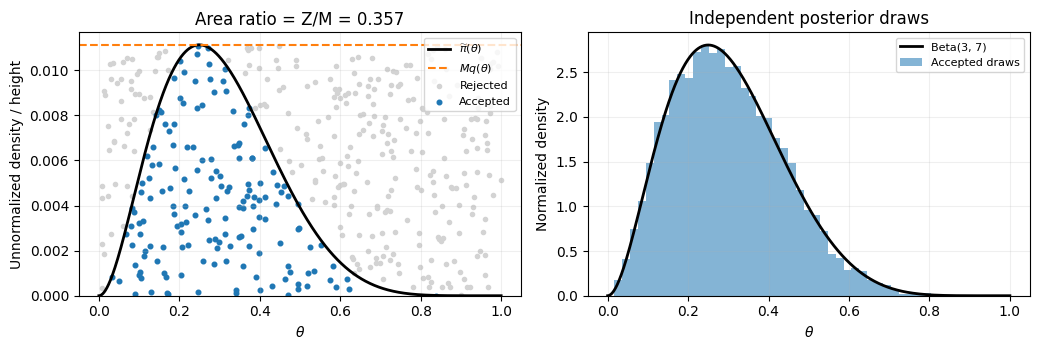

In [3]:
geometry_rng = np.random.default_rng(SEED + 1)
x_prop = geometry_rng.random(450)
heights = M*geometry_rng.random(450)
keep = heights < np.exp(log_target(x_prop))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
axes[0].scatter(x_prop[~keep], heights[~keep], s=9, color='lightgray', label='Rejected')
axes[0].scatter(x_prop[keep], heights[keep], s=11, color='tab:blue', label='Accepted')
axes[0].plot(grid, np.exp(log_target(grid)), color='black', lw=2,
             label=r'$\widetilde\pi(\theta)$')
axes[0].axhline(M, color='tab:orange', ls='--', label=r'$M q(\theta)$')
axes[0].set(xlabel=r'$\theta$', ylabel='Unnormalized density / height',
            title=f'Area ratio = Z/M = {P_ACCEPT:.3f}', ylim=(0, 1.05*M))
axes[0].legend(fontsize=8)
axes[1].hist(rejection_draws, bins=40, density=True, alpha=.55, label='Accepted draws')
axes[1].plot(grid, beta.pdf(grid, 3, 7), color='black', lw=2, label='Beta(3, 7)')
axes[1].set(xlabel=r'$\theta$', ylabel='Normalized density', title='Independent posterior draws')
axes[1].legend(fontsize=8)
save_show(fig, 'rejection_geometry')


Обсуждение. Почему нельзя просто уменьшить $M$, чтобы чаще принимать?
Если огибающая нарушена, алгоритм перестаёт давать целевую плотность.
Обрезание отношения через `min(1, ratio)` не исправляет неправильную огибающую.
Проверка по сетке в коде — проверка реализации; глобальное условие здесь доказано
аналитически нахождением единственного максимума и поведением на границах.

В чём ограничение метода? В $d$ независимых копиях этого примера произведение
предложений и произведение огибающих дают вероятность принятия $(Z/M)^d$.
Например, при $d=10$ принимается уже очень малая доля предложений.
Это свойство выбранного предложения; более удачная огибающая может помочь.


In [4]:
table(['Размерность d', 'Вероятность принятия', 'Среднее число предложений'],
      [(d, P_ACCEPT**d, P_ACCEPT**(-d)) for d in [1, 2, 5, 10, 20]])


| Размерность d | Вероятность принятия | Среднее число предложений |
| --- | --- | --- |
| 1 | 0.35674 | 2.8032 |
| 2 | 0.12726 | 7.8577 |
| 5 | 0.0057778 | 173.08 |
| 10 | 3.3382e-05 | 29956 |
| 20 | 1.1144e-09 | 8.9735e+08 |

## 2. Стационарность и сходимость — разные утверждения · 8–15 минут

Для конечной цепи используем строковую конвенцию:
$$P_{ij}=\Pr(X_{t+1}=j\mid X_t=i),\quad \sum_jP_{ij}=1,
\quad \mu_{t+1}=\mu_t P.$$
Стационарность означает $\pi P=\pi$. Детальное равновесие требует
$\pi_iP_{ij}=\pi_jP_{ji}$ для каждой пары и влечёт стационарность.
Оно достаточно, но не необходимо.

Для конечной неприводимой апериодической цепи стационарное распределение
единственно и $\mu_0P^t\to\pi$ при любом начальном распределении.
Два контрпримера объясняют роль условий:

1. Детерминированное переключение $0\leftrightarrow1$ неприводимо,
   стационарное распределение единственно и равномерно, но период равен 2.
   Из фиксированной точки распределения чередуются; частоты посещений
   всё же стремятся к $(1/2,1/2)$.
2. $P=I$: любая мера стационарна, но цепь никогда не покидает начальную точку.
   Даже детальное равновесие выполняется для любой $\pi$.

В первом рисунке считаем распределения точным умножением матриц. Это не
гистограммы одной случайной траектории.


P =
 [[0.5     0.3     0.2    ]
 [0.12    0.7     0.18   ]
 [0.13333 0.3     0.56667]]
pi P = [0.2 0.5 0.3]
Directed lazy cycle: stationary uniform, but flux 0→1 = 1/6 and 1→0 = 0.


| Начальное состояние | TV при t=0 | TV при t=5 | TV при t=25 |
| --- | --- | --- | --- |
| 0 | 0.8 | 0.0060246 | 5.6295e-11 |
| 1 | 0.5 | 0.00512 | 5.6295e-11 |
| 2 | 0.7 | 0.005723 | 5.6295e-11 |

| t | P(X_t=0) | Частота 0 среди X_1,...,X_t |
| --- | --- | --- |
| 5 | 0 | 0.4 |
| 6 | 1 | 0.5 |
| 25 | 0 | 0.48 |
| 26 | 1 | 0.5 |

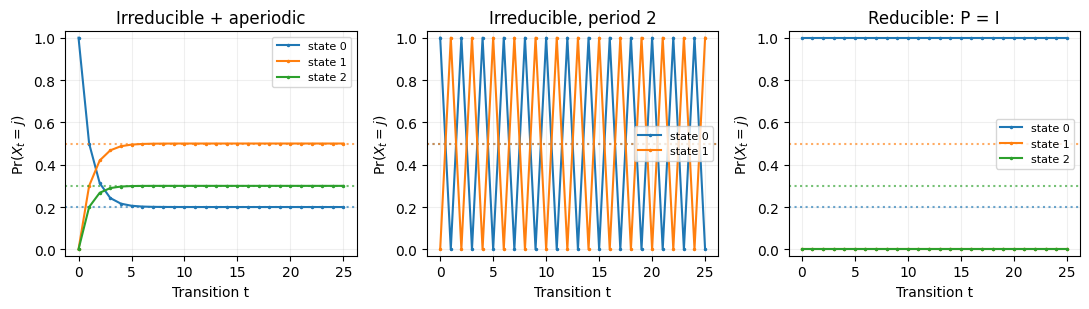

In [5]:
pi = np.array([.2, .5, .3])
# Symmetric probability flux F_ij = pi_i P_ij gives detailed balance.
flux = np.array([[.10, .06, .04], [.06, .35, .09], [.04, .09, .17]])
P = flux / pi[:, None]
P_periodic = np.array([[0., 1.], [1., 0.]])
P_reducible = np.eye(3)
P_cycle = np.array([[.5, .5, 0.], [0., .5, .5], [.5, 0., .5]])

def distributions(P, initial, steps):
    history = [np.array(initial, dtype=float)]
    for _ in range(steps):
        history.append(history[-1] @ P)
    return np.array(history)

for kernel in [P, P_periodic, P_reducible, P_cycle]:
    np.testing.assert_allclose(kernel.sum(axis=1), 1)
    assert np.all(kernel >= 0)
np.testing.assert_allclose(pi @ P, pi)
np.testing.assert_allclose(pi[:, None]*P, (pi[:, None]*P).T)
pi_cycle = np.ones(3)/3
np.testing.assert_allclose(pi_cycle @ P_cycle, pi_cycle)
assert not np.allclose(pi_cycle[:, None]*P_cycle, (pi_cycle[:, None]*P_cycle).T)
print('P =\n', P)
print('pi P =', pi @ P)
print('Directed lazy cycle: stationary uniform, but flux 0→1 = 1/6 and 1→0 = 0.')

# Exact marginal convergence from all three point starts.
tv_rows = []
for start in range(3):
    history = distributions(P, np.eye(3)[start], 25)
    tv = [.5*np.abs(history[t]-pi).sum() for t in [0, 5, 25]]
    tv_rows.append([start] + tv)
table(['Начальное состояние', 'TV при t=0', 'TV при t=5', 'TV при t=25'], tv_rows)

# In this deterministic alternating chain each law is also a visit indicator.
# Occupation frequencies average X_1,...,X_t; they are not the law at time t.
periodic_history = distributions(P_periodic, [1, 0], 26)
occupation_zero = np.cumsum(periodic_history[1:, 0])/np.arange(1, 27)
table(['t', 'P(X_t=0)', 'Частота 0 среди X_1,...,X_t'],
      [[t, periodic_history[t, 0], occupation_zero[t-1]] for t in [5, 6, 25, 26]])

histories = [distributions(P, [1, 0, 0], 25),
             distributions(P_periodic, [1, 0], 25),
             distributions(P_reducible, [1, 0, 0], 25)]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
titles = ['Irreducible + aperiodic', 'Irreducible, period 2', 'Reducible: P = I']
references = [pi, np.array([.5, .5]), pi]
for ax, history, reference, title in zip(axes, histories, references, titles):
    for j in range(history.shape[1]):
        line, = ax.plot(history[:, j], marker='.', ms=3, label=f'state {j}')
        ax.axhline(reference[j], ls=':', color=line.get_color(), alpha=.65)
    ax.set(xlabel='Transition t', ylabel=r'$\Pr(X_t=j)$', title=title, ylim=(-.03, 1.03))
    ax.legend(fontsize=8)
save_show(fig, 'markov_convergence')


Вопросы и ответы.

| Вопрос | Ответ |
|---|---|
| Если запустить периодическую цепь из стационарного распределения? | Каждый $X_t$ имеет стационарное распределение, хотя соседние состояния зависимы. |
| Зачем третий пример, если детальное равновесие доказано? | Равновесие не гарантирует неприводимость и единственность целевой меры. |
| Цикл $0\to1\to2\to0$ с вероятностью остаться $1/2$ корректен? | Да: равномерная мера стационарна, цепь неприводима и апериодична. Обратимость не обязательна. |
| Что измеряет $\|\mu_t-\pi\|_{TV}$? | Расхождение распределений в момент $t$, равное $\tfrac12\sum_j|\mu_t(j)-\pi(j)|$. |

В непрерывном пространстве нужно уточнять условия (например, положительную
харрисовскую возвратность и апериодичность); конечную теорему нельзя переносить
на произвольную непрерывную цепь только по формальному сходству.


## 3. Алгоритм Гиббса: правильная плотность и медленное движение · 15–30 минут

Пусть целевая плотность
$$\pi(x,y)=\mathcal N\!\left(\binom xy;0,
\begin{pmatrix}1&\rho\\\rho&1\end{pmatrix}\right),\quad |\rho|<1.$$
Выделение квадрата в экспоненте даёт
$$x\mid y\sim\mathcal N(\rho y,1-\rho^2),\qquad
y\mid x\sim\mathcal N(\rho x,1-\rho^2).$$
Один полный проход (sweep) систематического Гиббса:
$$x_{t+1}=\rho y_t+\sqrt{1-\rho^2}\,\varepsilon_{t,1},\quad
y_{t+1}=\rho x_{t+1}+\sqrt{1-\rho^2}\,\varepsilon_{t,2}.$$
Во второй формуле используется новое $x_{t+1}$. В каждой строке сохранённой
выборки — состояние после полного прохода. Полушаги нужны только для геометрии.

Каждое координатное ядро сохраняет $\pi$ и обратимо относительно $\pi$.
Их композиция сохраняет $\pi$, но в общем случае необратима. Случайный выбор
координаты с фиксированными, не зависящими от состояния вероятностями даёт
смесь обратимых ядер и потому обратим. Если считать каждый полушаг отдельным
тактом фиксированного обхода, ядро чередуется; мы считаем цепь по полным проходам.


In [6]:
def gibbs_gaussian(rho, n, rng, initial=(0., 0.)):
    """Return states after full x-then-y sweeps; no thinning."""
    if abs(rho) >= 1:
        raise ValueError('Нужно |rho| < 1')
    x, y = np.asarray(initial, dtype=float)
    noise_sd = np.sqrt(1-rho*rho)
    samples = np.empty((n, 2))
    for t in range(n):
        x = rho*y + noise_sd*rng.normal()
        y = rho*x + noise_sd*rng.normal()
        samples[t] = x, y
    return samples

def half_step_path(samples, initial):
    """Insert the horizontal x update before each vertical y update."""
    previous = np.vstack([initial, samples[:-1]])
    path = np.empty((2*len(samples)+1, 2))
    path[0] = initial
    path[1::2] = np.column_stack([samples[:, 0], previous[:, 1]])
    path[2::2] = samples
    return path

# Check Gaussian invariance exactly via linear transition and noise covariance.
for rho in [.5, .95, .99]:
    Sigma = np.array([[1., rho], [rho, 1.]])
    A = np.array([[0., rho], [0., rho*rho]])
    Q = (1-rho*rho)*np.array([[1., rho], [rho, 1+rho*rho]])
    np.testing.assert_allclose(A @ Sigma @ A.T + Q, Sigma, atol=1e-12)
    assert not np.allclose(A @ Sigma, Sigma @ A.T)

# Regression check: the second coordinate must use the newly drawn first.
reference_rng = np.random.default_rng(123)
eps = reference_rng.normal(size=2)
x_expected = .8*2 + .6*eps[0]
y_expected = .8*x_expected + .6*eps[1]
np.testing.assert_allclose(gibbs_gaussian(.8, 1, np.random.default_rng(123), (1, 2)),
                           [[x_expected, y_expected]])
print('Проверены инвариантность ковариации и использование новой координаты.')


Проверены инвариантность ковариации и использование новой координаты.


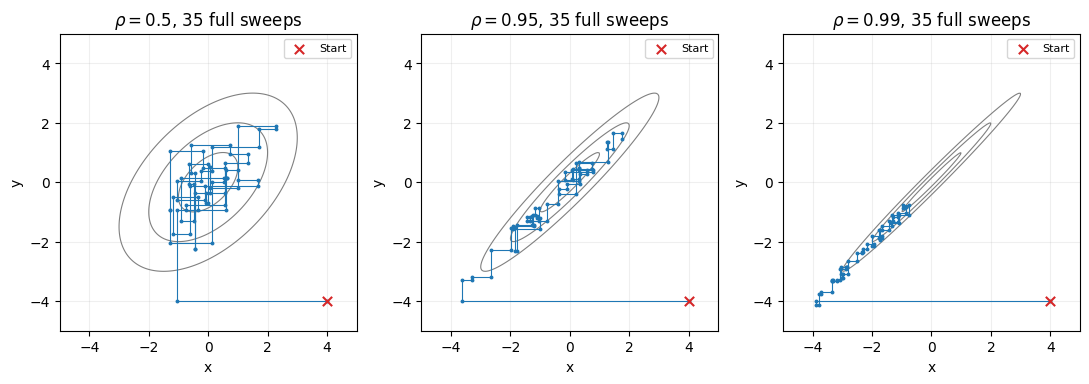

In [7]:
rhos = [.5, .95, .99]
initial = (4., -4.)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.7))
xx, yy = np.meshgrid(np.linspace(-5, 5, 250), np.linspace(-5, 5, 250))
for index, (rho, ax) in enumerate(zip(rhos, axes)):
    mahalanobis = (xx**2 - 2*rho*xx*yy + yy**2)/(1-rho*rho)
    ax.contour(xx, yy, mahalanobis, levels=[1, 4, 9], colors='gray', linewidths=.8)
    path_samples = gibbs_gaussian(rho, 35, np.random.default_rng(SEED+10+index), initial)
    path = half_step_path(path_samples, initial)
    ax.plot(path[:, 0], path[:, 1], '-o', ms=1.8, lw=.8, color='tab:blue')
    ax.scatter(*initial, color='tab:red', marker='x', s=45, zorder=5, label='Start')
    ax.set(xlabel='x', ylabel='y', title=fr'$\rho={rho}$, 35 full sweeps',
           xlim=(-5, 5), ylim=(-5, 5), aspect='equal')
    ax.legend(fontsize=8)
save_show(fig, 'gibbs_geometry')


При большой $\rho$ условные дисперсии малы. Цепь быстро попадает в узкую
диагональную область и затем медленно движется вдоль неё. Узкая область
с высокой плотностью не означает, что среднее уже вычислено точно.

Для координаты $y$ на концах проходов подставим первое обновление во второе:
$$y_{t+1}=\rho^2y_t+
\sqrt{1-\rho^2}\,(\rho\varepsilon_{t,1}+\varepsilon_{t,2}).$$
Это AR(1) с коэффициентом $a=\rho^2$ и дисперсией шума $1-\rho^4$.
При стационарном старте $\operatorname{Corr}(y_t,y_{t+k})=\rho^{2k}$; та же
автокорреляция у записанной координаты $x$. Поэтому для оценки среднего координаты
$$\tau=1+2\sum_{k\ge1}\rho^{2k}=\frac{1+\rho^2}{1-\rho^2},\qquad
N_{\rm eff}\approx\frac N\tau,\qquad
\operatorname{MCSE}(\bar y)\approx\sqrt{\frac\tau N}.$$
Это асимптотические формулы для выбранной функции $f(x,y)=y$.
Здесь её стационарная дисперсия равна 1. Для других функций, например
$f=y^2$, автокорреляции и эффективный размер выборки будут другими.

Стационарный старт в следующем эксперименте сгенерирован напрямую из известной
нормали, чтобы отделить зависимость от начального смещения. Прямой сэмплер
используется только как контроль для этой учебной модели.


In [8]:
def autocorrelation(values, max_lag=200):
    values = np.asarray(values, dtype=float)
    centered = values-values.mean()
    n = len(values)
    # Zero padding prevents circular wrap-around in the FFT convolution.
    fft_size = 1 << (2*n-1).bit_length()
    spectrum = np.fft.rfft(centered, n=fft_size)
    sums = np.fft.irfft(spectrum*np.conjugate(spectrum), n=fft_size)[:max_lag+1]
    # Common denominator; finite-lag estimate, not a proof of convergence.
    return sums/sums[0]

def batch_means_mcse(values, batches=50):
    """Non-overlapping batch means; useful only if batches are long enough."""
    values = np.asarray(values)
    batch_size = len(values)//batches
    if batch_size < 2:
        raise ValueError('Слишком короткая цепь')
    used = batches*batch_size
    batch_averages = values[:used].reshape(batches, batch_size).mean(axis=1)
    return batch_averages.std(ddof=1)/np.sqrt(batches)

N = 30000
chains = {}
summary = []
for index, rho in enumerate(rhos):
    rng = np.random.default_rng(SEED+30+index)
    start = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]])
    chain = gibbs_gaussian(rho, N, rng, start)
    chains[rho] = chain
    tau = (1+rho*rho)/(1-rho*rho)
    y = chain[:, 1]
    iid_se = y.std(ddof=1)/np.sqrt(N)
    mcse = batch_means_mcse(y)
    empirical_ess = y.var(ddof=1)/mcse**2
    summary.append([rho, y.mean(), N/tau, empirical_ess,
                    iid_se, np.sqrt(tau/N), mcse])
table(['rho', 'Среднее y (истина 0)', 'ESS: точная асимпт.',
       'ESS: batch means', 'SE, если ошибочно iid', 'MCSE: точная асимпт.',
       'MCSE: batch means'], summary)
print('Один полный проход = два координатных обновления.')
print('Для rho=.99 длина batch = 600, всего около 6 tau: оценка MCSE сама шумна.')


| rho | Среднее y (истина 0) | ESS: точная асимпт. | ESS: batch means | SE, если ошибочно iid | MCSE: точная асимпт. | MCSE: batch means |
| --- | --- | --- | --- | --- | --- | --- |
| 0.5 | 0.0003267 | 18000 | 17435 | 0.0057877 | 0.0074536 | 0.007592 |
| 0.95 | -0.0047451 | 1537.5 | 1504.6 | 0.0058111 | 0.025503 | 0.025948 |
| 0.99 | 0.031045 | 301.5 | 297.48 | 0.0060371 | 0.057591 | 0.060627 |

Один полный проход = два координатных обновления.
Для rho=.99 длина batch = 600, всего около 6 tau: оценка MCSE сама шумна.


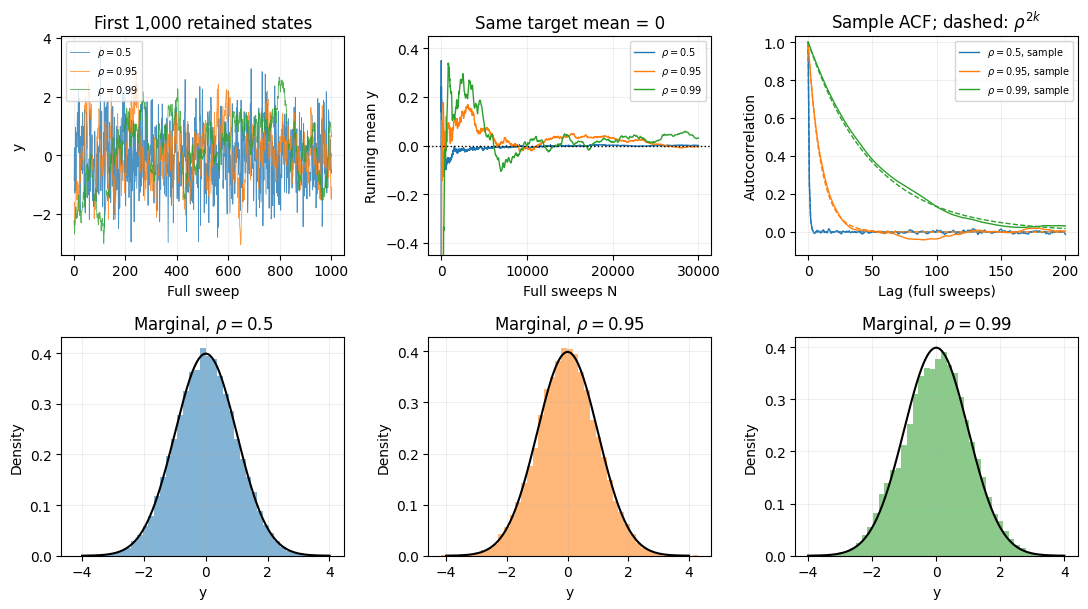

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))
lags = np.arange(201)
colors = ['tab:blue', 'tab:orange', 'tab:green']
for index, (rho, color) in enumerate(zip(rhos, colors)):
    y = chains[rho][:, 1]
    axes[0, 0].plot(np.arange(1, 1001), y[:1000], color=color, lw=.6,
                    alpha=.8, label=fr'$\rho={rho}$')
    count = np.arange(1, len(y)+1)
    axes[0, 1].plot(count, np.cumsum(y)/count, color=color, lw=1,
                    label=fr'$\rho={rho}$')
    axes[0, 2].plot(lags, autocorrelation(y), color=color, lw=1,
                    label=fr'$\rho={rho}$, sample')
    axes[0, 2].plot(lags, rho**(2*lags), color=color, ls='--', lw=1)
    axes[1, index].hist(y, bins=45, density=True, alpha=.55, color=color)
    marginal_grid = np.linspace(-4, 4, 300)
    axes[1, index].plot(marginal_grid, norm.pdf(marginal_grid), color='black')
    axes[1, index].set(xlabel='y', ylabel='Density',
                      title=fr'Marginal, $\rho={rho}$')
axes[0, 0].set(xlabel='Full sweep', ylabel='y', title='First 1,000 retained states')
axes[0, 1].axhline(0, color='black', ls=':', lw=1)
axes[0, 1].set(xlabel='Full sweeps N', ylabel='Running mean y', title='Same target mean = 0',
               ylim=(-.45, .45))
axes[0, 2].set(xlabel='Lag (full sweeps)', ylabel='Autocorrelation',
               title=r'Sample ACF; dashed: $\rho^{2k}$', ylim=(-.12, 1.03))
for ax in axes[0]:
    ax.legend(fontsize=7)
save_show(fig, 'gibbs_diagnostics')


Как читать таблицу и рисунок.

- Все три цепи сохраняют одну и ту же семью нормальных маргиналей $N(0,1)$,
  но дают разную точность среднего при одинаковом числе проходов.
- Для $\rho=.99$ теоретическое $\tau\approx99.5$: 30 000 проходов по
  точности среднего примерно соответствуют лишь 302 независимым точкам.
- Столбец batch means — оценка по конечной цепи. Её отличие от точного
  асимптотического ориентира не означает ошибку сэмплера.
- Гистограмма проверяет только отдельное маргинальное распределение.
  Сходимость одной кривой среднего или маленькая видимая ACF также не доказывают,
  что цепь исследовала всё пространство. В неизвестной модели нужны несколько
  стартов, диагностики и понимание геометрии.
- Удаление начального участка может ослабить начальное смещение, но не делает
  оставшиеся состояния независимыми. Прореживание теряет вычисленные состояния;
  оно не улучшает точность автоматически при фиксированном вычислительном бюджете.

Почему Гиббс обычно не отбрасывает состояния? Здесь каждый шаг сэмплирует из
точного полного условного распределения. Это не гарантирует быстрого перемещения
между отдалёнными областями. Если полные условные распределения недоступны для
прямого сэмплирования, понадобится другой шаг — тема второго семинара.


### Отдельно: начальное смещение и стационарность

Ниже три цепи при $\rho=.99$ начинаются в разных точках. Для выбранного
систематического обхода $\mathbb E[y_t]=\rho^{2t}y_0$ точно; это позволяет
увидеть время забывания старта. Стационарный закон существует с самого начала
как свойство ядра, но распределение запущенной из точки цепи не равно ему
на каждом конечном шаге. Универсального числа шагов «разогрева» нет.
Эту ячейку можно показать вместо подробностей реализации оценивания MCSE.


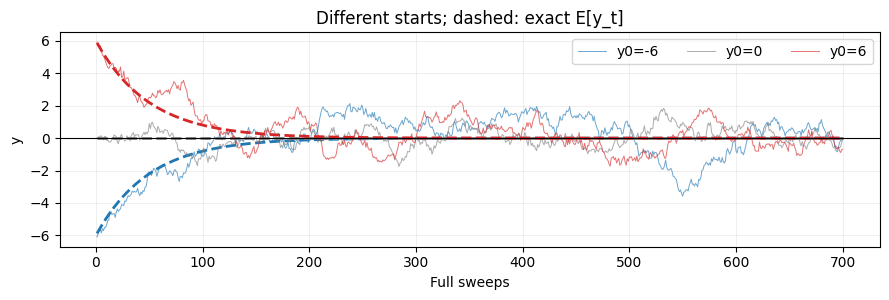

In [10]:
rho = .99
fig, ax = plt.subplots(figsize=(9, 3.1))
for index, start in enumerate([(-6., -6.), (0., 0.), (6., 6.)]):
    sample = gibbs_gaussian(rho, 700, np.random.default_rng(SEED+60+index), start)
    color = ['tab:blue', 'tab:gray', 'tab:red'][index]
    t = np.arange(1, 701)
    ax.plot(t, sample[:, 1], color=color, lw=.7, alpha=.65, label=f'y0={start[1]:.0f}')
    ax.plot(t, rho**(2*t)*start[1], color=color, ls='--', lw=2)
ax.axhline(0, color='black', lw=.8)
ax.set(xlabel='Full sweeps', ylabel='y', title='Different starts; dashed: exact E[y_t]')
ax.legend(ncol=3)
fig.tight_layout()
plt.show()


## Приложение. Байесовская модель: нормальные наблюдения

Вне 30-минутного маршрута; все ячейки также заполнены и выполнены.
Пусть $z_i\mid\mu,\tau\sim N(\mu,\tau^{-1})$, где $\tau$ — точность.
Выберем сопряжённый совместный prior
$$\tau\sim\operatorname{Gamma}(a_0,b_0),\qquad
\mu\mid\tau\sim N(\mu_0,(\kappa_0\tau)^{-1}).$$
В Gamma второй параметр — rate:
$p(\tau)\propto\tau^{a-1}e^{-b\tau}$, $\mathbb E\tau=a/b$.
После наблюдений
$$\kappa_n=\kappa_0+n,\quad
\mu_n=\frac{\kappa_0\mu_0+n\bar z}{\kappa_n},\quad
a_n=a_0+n/2,$$
$$b_n=b_0+\tfrac12\sum_i(z_i-\bar z)^2+
\frac{\kappa_0n}{2\kappa_n}(\bar z-\mu_0)^2.$$
Полные условные распределения для Гиббса:
$$\mu\mid\tau,z\sim N(\mu_n,(\kappa_n\tau)^{-1}),$$
$$\tau\mid\mu,z\sim\operatorname{Gamma}
\left(a_n+\tfrac12,\ b_n+\tfrac{\kappa_n}{2}(\mu-\mu_n)^2\right).$$
Добавка $1/2$ в форме Gamma возникает из нормирующего множителя
$\sqrt\tau$ в $p(\mu\mid\tau,z)$. Маргинальный постериор точности имеет
форму $\operatorname{Gamma}(a_n,b_n)$, без этой добавки. NumPy принимает
`scale=1/rate`, а не rate.


| Постериорная величина | Гиббс | Точный ориентир |
| --- | --- | --- |
| E[mu | z] | 1.2465 | 1.2472 |
| Var[mu | z] | 0.013515 | 0.013719 |
| E[tau | z] | 2.1363 | 2.1342 |

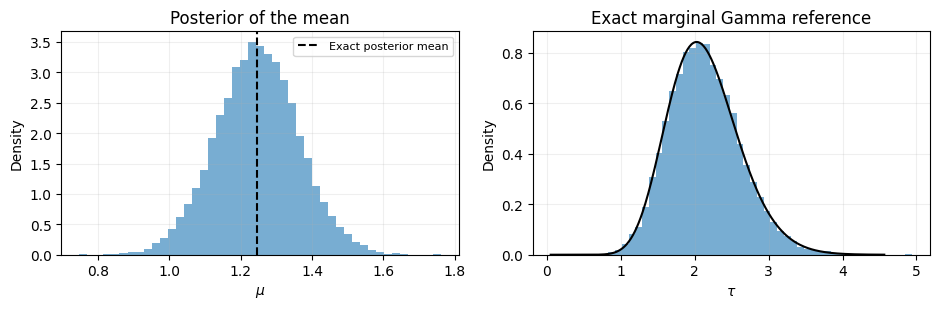

In [11]:
data_rng = np.random.default_rng(SEED+100)
observations = data_rng.normal(1.5, .8, size=35)
mu0, kappa0, a0, b0 = 0., 1., 2., 2.
n = len(observations)
zbar = observations.mean()
kappan = kappa0+n
mun = (kappa0*mu0+n*zbar)/kappan
an = a0+n/2
bn = b0+.5*np.sum((observations-zbar)**2)+.5*kappa0*n/kappan*(zbar-mu0)**2

def gibbs_normal_gamma(n_draws, rng, initial_tau=1.):
    tau = float(initial_tau)
    samples = np.empty((n_draws, 2))
    for t in range(n_draws):
        mu = rng.normal(mun, np.sqrt(1/(kappan*tau)))
        rate = bn+.5*kappan*(mu-mun)**2
        tau = rng.gamma(shape=an+.5, scale=1/rate)
        samples[t] = mu, tau
    return samples

normal_gamma = gibbs_normal_gamma(18000, np.random.default_rng(SEED+101))[1000:]
# Exact variance: E[1/tau]/kappan = bn / (kappan*(an-1)).
table(['Постериорная величина', 'Гиббс', 'Точный ориентир'], [
    ['E[mu | z]', normal_gamma[:, 0].mean(), mun],
    ['Var[mu | z]', normal_gamma[:, 0].var(ddof=1), bn/(kappan*(an-1))],
    ['E[tau | z]', normal_gamma[:, 1].mean(), an/bn]])
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2))
axes[0].hist(normal_gamma[:, 0], bins=45, density=True, alpha=.6)
axes[0].axvline(mun, color='black', ls='--', label='Exact posterior mean')
axes[0].set(xlabel=r'$\mu$', ylabel='Density', title='Posterior of the mean')
axes[0].legend(fontsize=8)
tau_grid = np.linspace(.05, np.quantile(normal_gamma[:, 1], .999)*1.15, 350)
axes[1].hist(normal_gamma[:, 1], bins=45, density=True, alpha=.6)
axes[1].plot(tau_grid, gamma.pdf(tau_grid, a=an, scale=1/bn), color='black')
axes[1].set(xlabel=r'$\tau$', ylabel='Density', title='Exact marginal Gamma reference')
fig.tight_layout()
plt.show()


На следующем семинаре: как строить переход, когда прямое сэмплирование
из полных условных распределений затруднено; алгоритмы Метрополиса,
Метрополиса–Гастингса и гамильтонова динамика.

Источники для чтения:

- [K. Sigman, Acceptance-Rejection Method](https://www.columbia.edu/~ks20/4703-Sigman/4703-07-Notes-ARM.pdf),
  с. 1–2: условие огибающей, доказательство и вероятность принятия.
- [University of Cambridge, Markov Chains](https://www.statslab.cam.ac.uk/~rrw1/markov/M.pdf):
  конечные цепи, стационарность, обратимость и сходимость.
- [C. Geyer, Markov Chain Monte Carlo Lecture Notes](https://www.stat.umn.edu/geyer/8501/markov.pdf),
  разделы 5.4 и 5.9: алгоритм Гиббса, систематический и случайный обход,
  Monte Carlo standard error.
